In [21]:
from scipy.signal import savgol_filter
import matplotlib.pyplot as plt
import pandas as pd
import os

In [22]:
input_path = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/pre_processing/espectros_transformada_log.csv"
output_dir = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/pre_processing"
output_path = os.path.join(output_dir, 'espectros_derivada_PrimeiraOrdem.csv')

In [23]:
df = pd.read_csv(input_path)
data = df.values

In [24]:
# Aplica a derivada de primerida ordem com Savitzky-Golay
data_derivada = savgol_filter(data, window_length=11, polyorder=2, deriv=1)
data_derivada

array([[-4.82200995e+00, -4.05676856e+00, -3.29152717e+00, ...,
        -4.67614787e-02, -5.54846978e-02, -6.42079168e-02],
       [-4.83617290e+00, -4.06832454e+00, -3.30047617e+00, ...,
        -3.18260162e-02, -3.70106596e-02, -4.21953031e-02],
       [ 3.16605029e-02,  2.84519155e-02,  2.52433280e-02, ...,
        -6.47932354e-02, -7.01387810e-02, -7.54843265e-02],
       ...,
       [-2.40089735e-03, -2.99871776e-03, -3.59653816e-03, ...,
        -4.57418334e-03, -5.87489379e-03, -7.17560425e-03],
       [-4.34657887e-03, -4.39728283e-03, -4.44798679e-03, ...,
        -1.27581501e-02, -1.66551416e-02, -2.05521331e-02],
       [ 4.49497909e-03,  2.72174104e-03,  9.48502987e-04, ...,
         3.02336213e-03,  3.03996945e-03,  3.05657676e-03]],
      shape=(92480, 256))

In [25]:
df_derivada = pd.DataFrame(data_derivada, columns=df.columns)

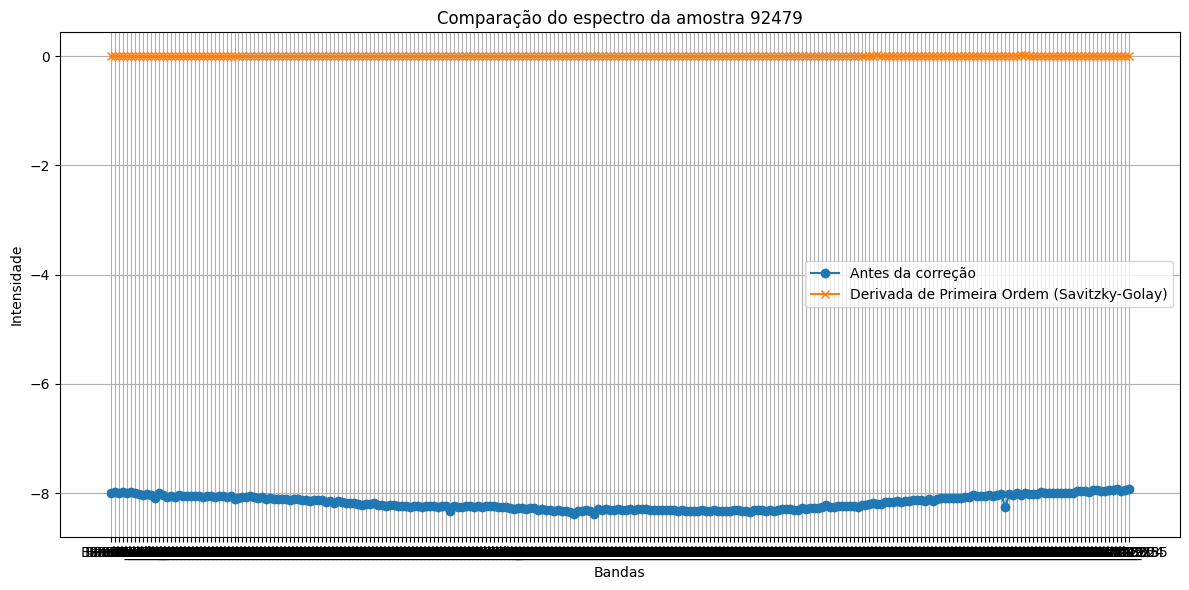

In [26]:
# Escolhe a última amostra
indice_amostra = df.shape[0] - 1

# Converte colunas para float se forem numéricas
try:
    bandas = df.columns.astype(float)
except:
    bandas = df.columns

plt.figure(figsize=(12, 6))
plt.plot(bandas, df.iloc[indice_amostra, :], label='Antes da correção', marker='o')
plt.plot(bandas, df_derivada.iloc[indice_amostra, :], label='Derivada de Primeira Ordem (Savitzky-Golay)', marker='x')
plt.xlabel('Bandas')
plt.ylabel('Intensidade')
plt.title(f'Comparação do espectro da amostra {indice_amostra}')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()